# Step 7d: Candidate 4 of 4, the Hurdle model

Same rules as before: winner by **R² in £** (MAE breaks ties), **5-fold CV on train only**, **250 Optuna trials**, features **R, F, M**, **test not touched**.

## The idea: split the problem in two
Step 5 showed that about half of the customers buy nothing in the next 6 months, and that *whether* they buy is very predictable from R, F, M. So instead of one model for everything:

| Stage | Question | Trained on | Output |
|---|---|---|---|
| 1. classifier | will they buy at all? | all customers (0/1) | `P(buy)` |
| 2. regressor | how much, *if* they buy? | **only the customers who bought** | expected £ |

**Prediction = P(buy) × expected spend if they buy.**

## Two variants of stage 2 (as in 7a: plain vs smearing)
- **raw £:** XGBoost regressor on £ directly.
- **log + smearing:** XGBoost on `log1p(£)`, converted back with Duan smearing. In 7a this was fragile because half the target was zero. Here stage 2 only sees buyers, so there are no zeros in its target.

Both stages are XGBoost and are tuned **jointly**: 10 settings (the usual five for each stage), 250 trials per variant. Code: `src/step7d_hurdle.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, cv_predictions, score_table
from step7a_ridge_log import LogRidge
from step7b_xgboost import XGBModel, oof_with_seed
from step7c_tweedie import XGBTweedie
from step7d_hurdle import (HurdleModel, suggest_hurdle, oof_parts, N_TRIALS,
                           ALPHA_7A_SMEAR, BEST_7B, BEST_7C)
from tuning import tune

pd.set_option("display.width", 220)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
X, y = build_rfm(train), train.target
ya = y.to_numpy()
buys = ya > 0

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. What each stage sees

Stage 1 sees everybody (roughly half buy). Stage 2 sees only the buyers, whose spend has no zeros:

customers 4,242 | buyers (stage 2 trains on these) 2,039 (48%) | non-buyers 2,203
skewness among buyers: raw 13.8 | log1p 0.36


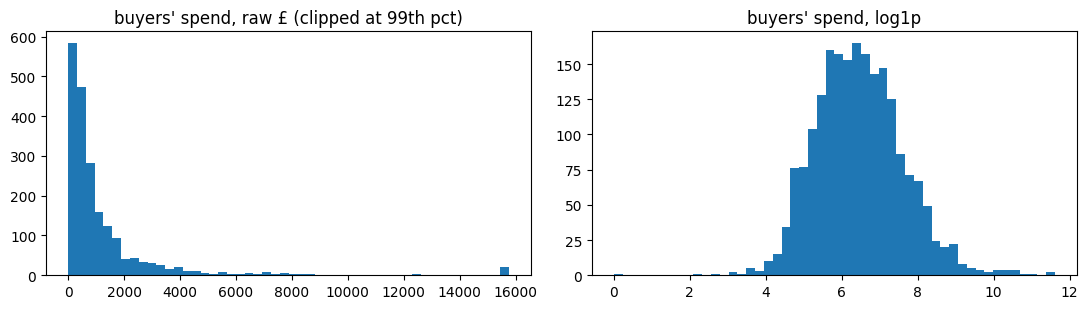

In [2]:
print(f"customers {len(ya):,} | buyers (stage 2 trains on these) {buys.sum():,} ({buys.mean():.0%}) | non-buyers {(~buys).sum():,}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(ya[buys].clip(max=np.quantile(ya[buys], 0.99)), bins=50); axes[0].set_title("buyers' spend, raw £ (clipped at 99th pct)")
axes[1].hist(np.log1p(ya[buys]), bins=50); axes[1].set_title("buyers' spend, log1p")
plt.tight_layout()
print(f"skewness among buyers: raw {pd.Series(ya[buys]).skew():.1f} | log1p {pd.Series(np.log1p(ya[buys])).skew():.2f}")

## 2. Tune both variants (joint, 250 trials each)

Hurdle, stage 2 raw GBP (7d): tuning score 0.529
   stage 1 {'n_estimators': 419, 'max_depth': 2, 'learning_rate': 0.1918, 'subsample': 0.5442, 'colsample_bytree': 0.9493}
   stage 2 {'n_estimators': 152, 'max_depth': 2, 'learning_rate': 0.0302, 'subsample': 0.3005, 'colsample_bytree': 0.6253}


Hurdle, stage 2 log+smear (7d): tuning score 0.567
   stage 1 {'n_estimators': 409, 'max_depth': 3, 'learning_rate': 0.0191, 'subsample': 0.8474, 'colsample_bytree': 0.7053}
   stage 2 {'n_estimators': 487, 'max_depth': 2, 'learning_rate': 0.0283, 'subsample': 0.4383, 'colsample_bytree': 0.736}


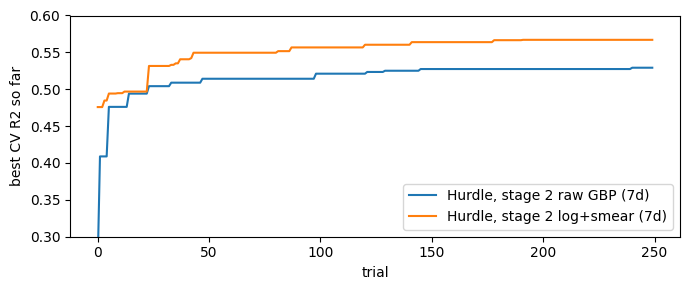

In [3]:
best, studies = {}, {}
for log2, label in ((False, "Hurdle, stage 2 raw GBP (7d)"), (True, "Hurdle, stage 2 log+smear (7d)")):
    st = tune(lambda log2=log2, **p: HurdleModel(log_stage2=log2, **p), suggest_hurdle, X, y, n_trials=N_TRIALS)
    best[label], studies[label] = st.best_params, st
    print(f"{label}: tuning score {st.best_value:.3f}")
    for stage, pre in (("stage 1", "c_"), ("stage 2", "r_")):
        print("  ", stage, {k[2:]: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items() if k.startswith(pre)})

fig, ax = plt.subplots(figsize=(7, 3))
for (label, st), c in zip(studies.items(), ["tab:blue", "tab:orange"]):
    ax.plot(np.maximum.accumulate([t.value for t in st.trials]), label=label, color=c)
ax.set_xlabel("trial"); ax.set_ylabel("best CV R2 so far"); ax.set_ylim(0.3, 0.6); ax.legend(); plt.tight_layout()

Both variants again prefer **shallow trees** (depth 2 for stage 2, depth 2 to 3 for stage 1). Several settings sit at an edge of their range (stage 2 `max_depth` 2 = the minimum, `subsample` 0.30 = the minimum in the raw variant, `n_estimators` 487 close to the 500 maximum in the log variant).

## 3. Compare (train CV)

In [4]:
preds = {n: cv_predictions(c, X, y) for n, c in BASELINES.items()}
preds["LogRidge + smearing (7a)"] = cv_predictions(lambda: LogRidge(ALPHA_7A_SMEAR, True), X, y)
preds["XGBoost raw GBP (7b)"] = cv_predictions(lambda: XGBModel(**BEST_7B), X, y)
preds["XGBoost Tweedie (7c)"] = cv_predictions(lambda: XGBTweedie(**BEST_7C), X, y)
for log2, label in ((False, "Hurdle, stage 2 raw GBP (7d)"), (True, "Hurdle, stage 2 log+smear (7d)")):
    preds[label] = cv_predictions(lambda log2=log2, b=best[label]: HurdleModel(log_stage2=log2, **b), X, y)

t = score_table(ya, preds)
t["total pred / total actual"] = [preds[k].sum() / ya.sum() for k in t.index]
display(t.round(3))
print("Same, without the 10 biggest customers:")
display(score_table(ya, preds, without_top=10).round(3))

,R2,MAE,Capture@20%,total pred / total actual
mean,-0.000,944.129,0.170,1.000
past_spend,0.746,523.153,0.739,1.001
LogRidge + smearing (7a),0.549,575.161,0.722,0.992
XGBoost raw GBP (7b),0.503,600.542,0.711,1.001
XGBoost Tweedie (7c),0.507,534.595,0.742,0.922
"Hurdle, stage 2 raw GBP (7d)",0.529,589.256,0.726,0.997
"Hurdle, stage 2 log+smear (7d)",0.567,534.409,0.746,0.969


Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686
LogRidge + smearing (7a),0.500,498.504,0.666
XGBoost raw GBP (7b),0.322,532.080,0.650
XGBoost Tweedie (7c),0.539,464.484,0.691
"Hurdle, stage 2 raw GBP (7d)",0.413,522.924,0.670
"Hurdle, stage 2 log+smear (7d)",0.494,468.907,0.693


How optimistic are the tuning scores? Same settings on 10 *other* fold splits:

In [5]:
honest = {}
for log2, label in ((False, "Hurdle, stage 2 raw GBP (7d)"), (True, "Hurdle, stage 2 log+smear (7d)")):
    rs = [r2(ya, oof_with_seed(lambda log2=log2, b=best[label]: HurdleModel(log_stage2=log2, **b), X, y, s)) for s in range(10)]
    honest[label] = rs
    print(f"{label}: tuning score {studies[label].best_value:.3f} | other fold splits mean {np.mean(rs):.3f}, sd {np.std(rs):.3f}, range {min(rs):.3f} to {max(rs):.3f}")

Hurdle, stage 2 raw GBP (7d): tuning score 0.529 | other fold splits mean 0.504, sd 0.023, range 0.476 to 0.548


Hurdle, stage 2 log+smear (7d): tuning score 0.567 | other fold splits mean 0.522, sd 0.026, range 0.462 to 0.561


The tuning scores are optimistic: 0.529 vs about 0.50 (raw) and 0.567 vs about 0.52 (log + smear). With 10 settings tuned at once, there is more room to get lucky on one fold split than in 7a (one setting) or 7b (five).

## 4. Where does the loss come from: stage 1 or stage 2?

The most useful thing about a two-stage model is that we can look inside. For each variant (out-of-fold):
- **Stage 1 AUC:** how well does it separate buyers from non-buyers? (0.5 = coin flip, 1.0 = perfect)
- **Stage 2 R² among real buyers:** how well does it predict the amount, given that they did buy?
- **R² if stage 1 were perfect:** use the *true* 0/1 instead of `P(buy)`, keep stage 2. This is the most R² that fixing stage 1 could ever give.

In [6]:
rows = {}
for log2, label in ((False, "Hurdle, stage 2 raw GBP (7d)"), (True, "Hurdle, stage 2 log+smear (7d)")):
    p, a = oof_parts(lambda log2=log2, b=best[label]: HurdleModel(log_stage2=log2, **b), X, y)
    rows[label] = {"stage 1 AUC": roc_auc_score(buys, p), "mean P(buy)": p.mean(), "actual share of buyers": buys.mean(),
                   "stage 2 R2 (buyers only)": r2(ya[buys], a[buys]), "stage 2 MAE (buyers only)": np.mean(np.abs(ya[buys] - a[buys])),
                   "R2 if stage 1 perfect": r2(ya, buys * a), "R2 actual": r2(ya, p * a)}
display(pd.DataFrame(rows).T.round(3))

,stage 1 AUC,mean P(buy),actual share of buyers,stage 2 R2 (buyers only),stage 2 MAE (buyers only),R2 if stage 1 perfect,R2 actual
"Hurdle, stage 2 raw GBP (7d)",0.760,0.481,0.481,0.519,969.209,0.544,0.529
"Hurdle, stage 2 log+smear (7d)",0.776,0.481,0.481,0.567,839.996,0.589,0.567


**Stage 1 is decent but not the bottleneck.** AUC is about 0.76 to 0.78, and the predicted share of buyers (0.481) matches the real share exactly. Even a *perfect* stage 1 would lift R² only from 0.567 to 0.589 (log variant). So the zeros are not what holds the R² down. **The amounts among the buyers are**: stage 2 explains only about 52 to 57% of the variation in buyers' spend.

## 5. Smearing is stable here (it was not in 7a)

In [7]:
m = HurdleModel(log_stage2=True, **best["Hurdle, stage 2 log+smear (7d)"]).fit(X, y)
pos = buys
res = np.log1p(ya[pos]) - m.reg_.predict(X[pos])
pd.DataFrame({"smearing factor S": [13.4, round(m.smear_, 2)], "largest log residual": [7.3, round(res.max(), 1)]},
             index=["7a Ridge on all customers (from 7a)", "7d stage 2, buyers only"])

,smearing factor S,largest log residual
7a Ridge on all customers (from 7a),13.40,7.3
"7d stage 2, buyers only",1.32,2.9


In 7a, half the customers had `log1p(0) = 0`, residuals reached +7, and the correction factor was 13.4. Removing the zeros from stage 2 shrinks the factor to about 1.3 and the largest residual to about 3. That is why the log + smear variant works well here, and why it beats the raw variant.

## 6. The giants again

In [8]:
top = np.argsort(-ya)[:10]
for n in ("past_spend", "XGBoost Tweedie (7c)", "Hurdle, stage 2 raw GBP (7d)", "Hurdle, stage 2 log+smear (7d)"):
    e = (ya - preds[n]) ** 2
    print(f"{n:34s} largest prediction {preds[n].max():>9,.0f} (actual max {ya.max():,.0f}) | share of squared error from the 10 biggest customers {e[top].sum() / e.sum():.0%}")

past_spend                         largest prediction   120,142 (actual max 110,668) | share of squared error from the 10 biggest customers 55%
XGBoost Tweedie (7c)               largest prediction    39,427 (actual max 110,668) | share of squared error from the 10 biggest customers 77%
Hurdle, stage 2 raw GBP (7d)       largest prediction    54,109 (actual max 110,668) | share of squared error from the 10 biggest customers 69%
Hurdle, stage 2 log+smear (7d)     largest prediction    50,360 (actual max 110,668) | share of squared error from the 10 biggest customers 71%


Same story as 7b and 7c: both stages are tree models, so the largest prediction stays near £50 to 54k while real spend reaches £110k, and about 70% of the squared error comes from the 10 biggest customers.

## What we learned

| Train CV | R² (tuning) | R² (honest, 10 other splits) | MAE (£) | Capture@20% | total pred / total actual | R² without top 10 |
|---|---|---|---|---|---|---|
| past_spend | **0.75** | 0.74 | 523 | 0.74 | 1.00 | **0.55** |
| Ridge on log1p + smearing (7a) | 0.55 | **0.56** | 575 | 0.72 | 0.99 | 0.50 |
| XGBoost raw £ (7b) | 0.50 | 0.48 | 600 | 0.71 | 1.00 | 0.32 |
| XGBoost Tweedie (7c) | 0.51 | 0.49 | 534 | 0.74 | 0.92 | 0.54 |
| Hurdle, stage 2 raw £ (7d) | 0.53 | 0.50 | 589 | 0.73 | 1.00 | 0.41 |
| **Hurdle, stage 2 log + smear (7d)** | **0.57** | 0.52 | **534** | **0.75** | 0.97 | 0.49 |

- **The Hurdle with log + smearing is the best of the four candidates on three of the four headline numbers:** tuning R² (0.567), MAE (534, tied with Tweedie) and Capture@20% (0.746). On the *honest* R², though, Ridge + smearing is still ahead (0.56 vs 0.52). The gap (0.04) is about one standard deviation of the fold-split noise, so **Ridge and Hurdle are not clearly separated on R²**.
- **No candidate beats past spend on R² (0.75), and the best ones tie it on ranking.** Hurdle's Capture@20% (0.746) vs past spend's (0.739) is a tie inside the ±0.04 noise.
- **Splitting the problem helped:** both Hurdle variants beat their single-model counterparts (raw: 0.53 vs 7b's 0.50; log + smear: 0.57 vs 7a's 0.55 on the tuning score), and the log variant's smearing finally works.
- **Stage 1 is not the bottleneck.** A perfect "who buys" model would add only about 0.02 of R². The weak point is the *amount among the biggest buyers*, which trees (stage 2 is trees too) cannot capture.
- **The tuning score is optimistic** (0.567 vs 0.522 honest) because 10 settings were tuned at once.

**Ideas to attack the giants (not tried, for discussion):** predict the ratio `target / Monetary` (let the linear rule supply the scale); a linear stage 2; or add features that separate big customers (step 8+).

**Next:** all four candidates are done. We should decide what to do with the result: improve the winner with the ratio idea and/or more features, then evaluate once on test.